In [1]:
!pip install yfinance

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   -------------- ------------------------- 0.8/2.1 MB 11.2 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 7.4 MB/s eta 0:00:00

   ---------------------------------------- 0/5 [peewee]
   ---------------------------------------- 0/5 [peewee]
   ---------------------------------------- 0/5 [peewee]
  Attempting uninstall: cffi
   ---------------------------------------- 0/5 [peewee]
    Found existing installation: cffi 1.17.1
   ---------------------------------------- 0/5 [peewee]
   -------- ------------------------------- 1/5 [cffi]
    Uninstalling cffi-1.17.1:
   -------- ------------------------------- 1/5 [cffi]
   -------- ------------------------------- 1/5 [cffi]
   -------- ------------------------------- 1/5 [cffi]
   -------- ------------------------------- 1/5 [cffi]
   -------- ------------------------------- 1/5 [cffi]
   -------- ------------------------------- 1/5 [cffi]
   

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 2.5.1 requires transformers<5.0.0,>=4.32.0, but you have transformers 5.12.1 which is incompatible.


In [74]:
import yfinance as yf
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [75]:
data_nvdia = yf.download ('NVDA',start = '2026-01-01', end = '2026-11-10')  ## takes upto n-1 days
data_nvdia.head(3)

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,NVDA,NVDA,NVDA,NVDA,NVDA
Date,,,,,
2026-01-02,188.409119,192.479580,187.820484,189.396798,148240500
2026-01-05,187.680832,193.177979,185.715430,191.312334,183529700
2026-01-06,186.802887,191.721370,186.383869,190.075228,176862600


In [76]:
data_nvdia.shape

(215, 5)

In [77]:
data_nvdia.columns = ['_'.join(cols).strip() for cols in data_nvdia.columns.values]
data_nvdia.head (3)

,Close_NVDA,High_NVDA,Low_NVDA,Open_NVDA,Volume_NVDA
Date,,,,,
2026-01-02,188.409119,192.479580,187.820484,189.396798,148240500
2026-01-05,187.680832,193.177979,185.715430,191.312334,183529700
2026-01-06,186.802887,191.721370,186.383869,190.075228,176862600


In [78]:
data_nvdia.isnull().sum()

Close_NVDA     0
High_NVDA      0
Low_NVDA       0
Open_NVDA      0
Volume_NVDA    0
dtype: int64

In [79]:
data_nvdia['z_score'] = (data_nvdia['Close_NVDA'] - data_nvdia['Close_NVDA'].mean()) / data_nvdia['Close_NVDA'].std()
data_nvdia.head(2)

,Close_NVDA,High_NVDA,Low_NVDA,Open_NVDA,Volume_NVDA,z_score
Date,,,,,,
2026-01-02,188.409119,192.479580,187.820484,189.396798,148240500,-0.840951
2026-01-05,187.680832,193.177979,185.715430,191.312334,183529700,-0.882894


In [80]:
def risk_catagories(z):
    if z > 1:
        return "High"
    elif z < -1 :
        return "Low"
    else: 
        return "Medium"

In [81]:
data_nvdia['Risk_Catagories'] = data_nvdia['z_score'].apply (risk_catagories)

In [82]:
data_nvdia.head(2)

,Close_NVDA,High_NVDA,Low_NVDA,Open_NVDA,Volume_NVDA,z_score,Risk_Catagories
Date,,,,,,,
2026-01-02,188.409119,192.479580,187.820484,189.396798,148240500,-0.840951,Medium
2026-01-05,187.680832,193.177979,185.715430,191.312334,183529700,-0.882894,Medium


In [83]:
data_nvdia = data_nvdia.reset_index()
data_nvdia.head(2)

,Date,Close_NVDA,High_NVDA,Low_NVDA,Open_NVDA,Volume_NVDA,z_score,Risk_Catagories
0,2026-01-02,188.409119,192.479580,187.820484,189.396798,148240500,-0.840951,Medium
1,2026-01-05,187.680832,193.177979,185.715430,191.312334,183529700,-0.882894,Medium


In [84]:
X = data_nvdia[['Close_NVDA','Low_NVDA','Open_NVDA','Volume_NVDA','z_score']]
y = data_nvdia['Risk_Catagories']

X_train, X_test,y_train,y_test = train_test_split (X,y,test_size = 0.3,random_state = 42)

In [85]:
X_train.shape

(150, 5)

In [86]:
X_test.shape

(65, 5)

In [87]:
knn = KNeighborsClassifier()
dt = DecisionTreeClassifier()
rf = RandomForestClassifier()
svm = SVC()

In [88]:
models = [knn , dt , rf , svm]
for model in models:
    model.fit(X_train,y_train)
    pred_model = model.predict(X_test)
    acc = accuracy_score (y_test,pred_model)
    print ('the accuracy of the ', model, 'is' ,acc*100)

the accuracy of the  KNeighborsClassifier() is 50.76923076923077
the accuracy of the  DecisionTreeClassifier() is 95.38461538461539
the accuracy of the  RandomForestClassifier() is 98.46153846153847
the accuracy of the  SVC() is 66.15384615384615


In [89]:
def check_outliers(data, column):
    sns.boxplot(x=data[column])
    plt.show()

In [90]:
cols = data_nvdia.columns

In [91]:
cols

Index(['Date', 'Close_NVDA', 'High_NVDA', 'Low_NVDA', 'Open_NVDA',
       'Volume_NVDA', 'z_score', 'Risk_Catagories'],
      dtype='object')

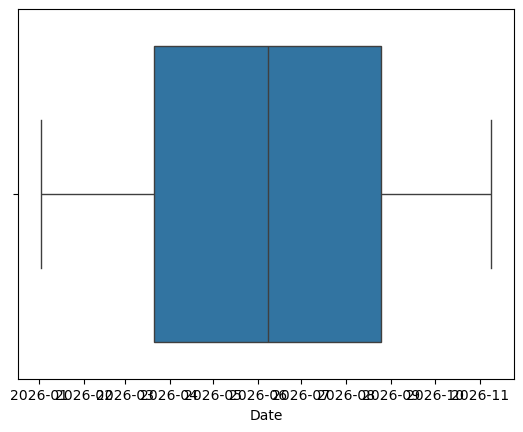

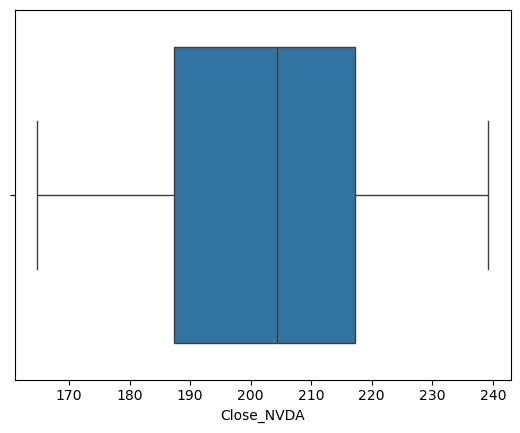

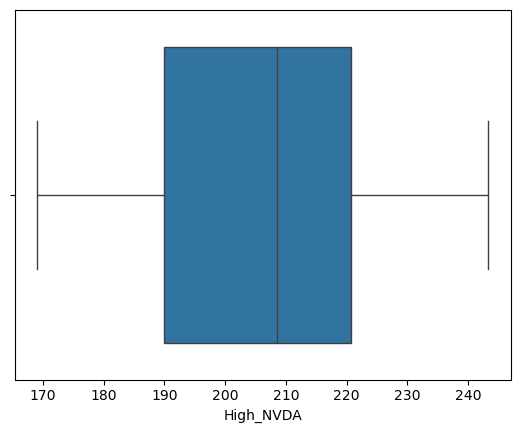

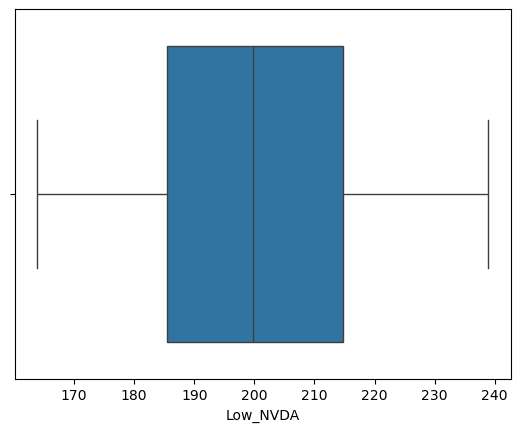

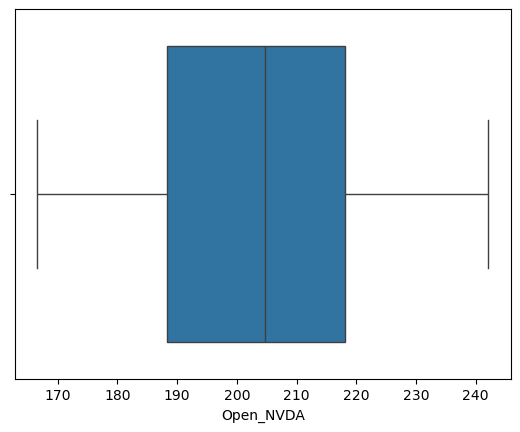

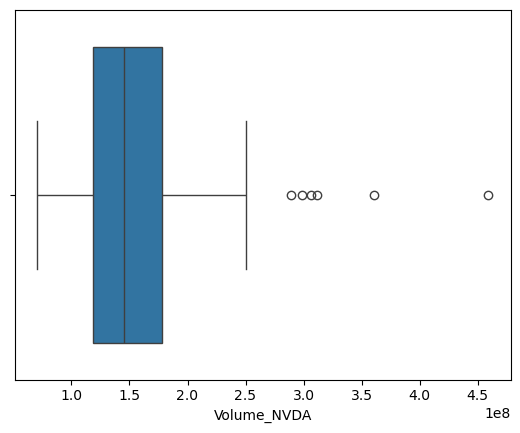

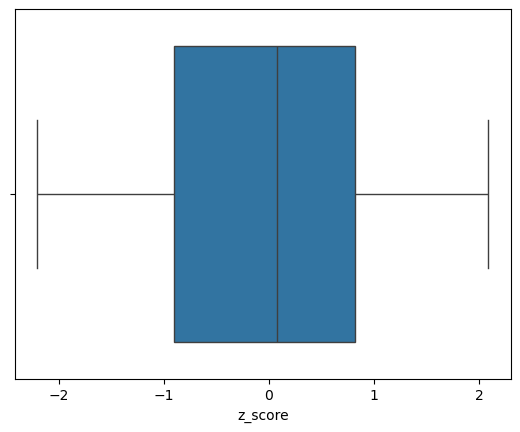

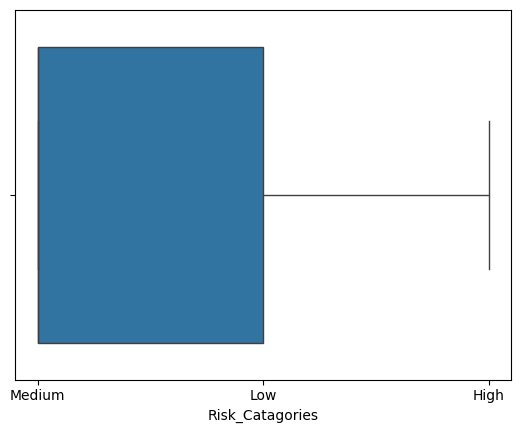

In [92]:
for i in cols:
    check_outliers(data_nvdia, i)

In [94]:

def quartiles(data, column):
    if pd.api.types.is_numeric_dtype(data[column]):

        Q1 = data[column].quantile(0.25)
        Q3 = data[column].quantile(0.75)
        Median = data[column].median()

        IQR = Q3 - Q1

        lower_bound = Q1 - (1.5 * IQR)
        upper_bound = Q3 + (1.5 * IQR)

        return lower_bound, Q1, Median, Q3, upper_bound

    else:
        Mode = data[column].mode()[0]
        return Mode

In [95]:
def impute_outliers (data,column):
    if pd.api.types.is_numeric_dtype(data[column]):
        lower_bound, Q1, Median, Q3, upper_bound = quartiles(data, column)
        outliers = ((data [column] > upper_bound) | (data[column] < lower_bound))
        data.loc[outliers, column] = Median
        check_outliers(data, column) 
    else:
        print ("Datatype is not numeric")

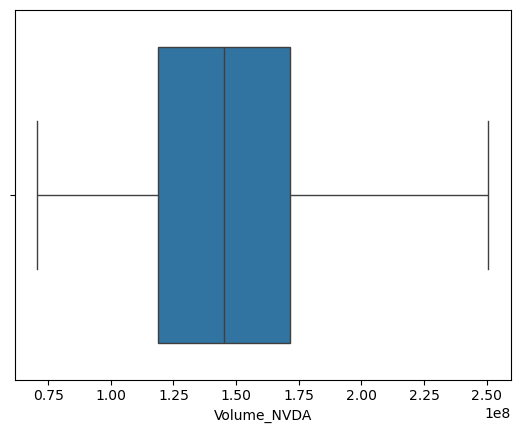

In [99]:
impute_outliers(data_nvdia, 'Volume_NVDA')

<Axes: xlabel='Volume_NVDA'>

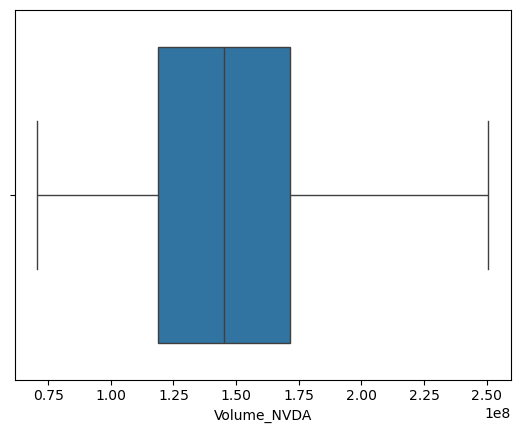

In [100]:
sns.boxplot(x = data_nvdia['Volume_NVDA'])